# Practical Assignment 6: Image Classification using CNN on Food Dataset

**Aim:** Build an image classification model using CNN on the Food-101 dataset.

**Key Concepts to Remember:**
1. **Class Filtering:** Pass `class_names=['pizza', 'hamburger', 'ice_cream', 'french_fries', 'sushi']` to filter categories.
2. **Feature Learning:** Deep convolutional filters learn texture and edge patterns specific to food types.
3. **Categorical Output:** Softmax probability distribution across all food categories.


In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
import tensorflow as tf
import numpy as np

# Step 1: Load Food-101 Images for Selected Categories
food_dir = r'd:/workspace01/4th year/DL/LabPracticesIV_DEEP_LEARNING/dataset/food-101/images'
selected_classes = ['french_fries', 'hamburger', 'ice_cream', 'pizza', 'sushi']

dataset = tf.keras.utils.image_dataset_from_directory(
    food_dir,
    class_names=selected_classes,
    image_size=(64, 64),
    batch_size=32,
    validation_split=0.2,
    subset='both',
    seed=42
)
train_ds, val_ds = dataset[0].take(25), dataset[1].take(10)

# Step 2: Build CNN Architecture
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(64, 64, 3)),
    tf.keras.layers.Rescaling(1.0 / 255.0),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(len(selected_classes), activation='softmax')
])
model.summary()

# Step 3: Compile and Train Model
model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
history = model.fit(train_ds, epochs=3, validation_data=val_ds, verbose=1)

# Step 4: Evaluate and Predict
loss, acc = model.evaluate(val_ds, verbose=0)
print(f'\nFood Classification Validation Accuracy: {acc*100:.2f}% | Loss: {loss:.4f}')

for images, labels in val_ds.take(1):
    preds = model.predict(images[:3], verbose=0)
    for i in range(3):
        pred_name = selected_classes[np.argmax(preds[i])]
        true_name = selected_classes[labels[i]]
        print(f'Food Item {i+1} -> Predicted: {pred_name:<12} | Actual: {true_name}')


Found 5000 files belonging to 5 classes.
Using 4000 files for training.
Using 1000 files for validation.
Model: "sequential_3"
┌─────────────────────────────────┬────────────────────────┬───────────────┐
│ Layer (type)                    │ Output Shape           │       Param # │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 31, 31, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 29, 29, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPool

### Step 5: Plot Training & Validation Loss and Accuracy Curves

Visualizing loss and accuracy trajectories across training epochs confirms convergence and checks for overfitting.


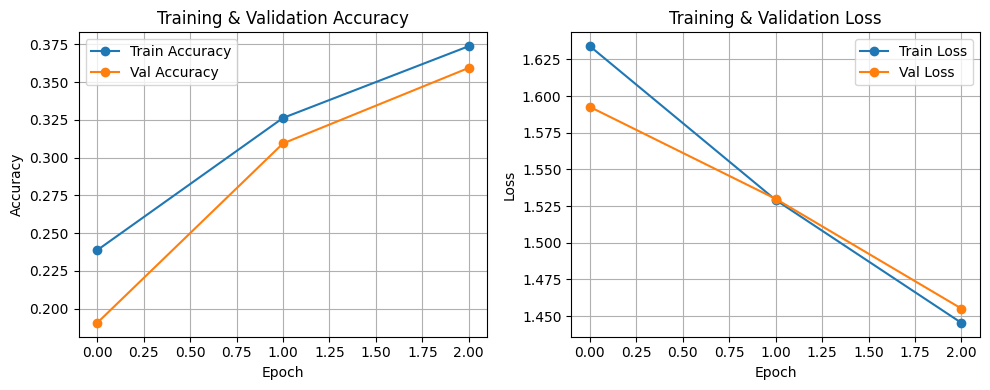

In [2]:
import matplotlib.pyplot as plt

# Step 5: Plot Training & Validation Accuracy and Loss Curves
plt.figure(figsize=(10, 4))

# Subplot 1: Accuracy
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy', marker='o')
plt.plot(history.history['val_accuracy'], label='Val Accuracy', marker='o')
plt.title('Training & Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

# Subplot 2: Loss
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss', marker='o')
plt.plot(history.history['val_loss'], label='Val Loss', marker='o')
plt.title('Training & Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()
